# CS 6220 — Homework 2: Report Experiments

Plots and tables for the report questions. All implementations (data generator, linear regression, regression tree, RMSE) come from [`homework_2.ipynb`](homework_2.ipynb), which is loaded below so the results match that code exactly.

In [1]:
%%capture
# load generate_noisy_dataset, split_dataset, fit, predict, evaluate_model, RegressionTree
%run homework_2.ipynb

In [2]:
import warnings

# NumPy 2.0 with Apple's Accelerate BLAS (Apple Silicon) emits spurious
# "divide by zero / overflow / invalid value encountered in matmul" warnings.
# The results are unaffected (verified against np.linalg.lstsq), so only these are silenced.
warnings.filterwarnings('ignore', message='.*encountered in matmul', category=RuntimeWarning)

## Setup

- True functions: linear `f(x) = 2x + 1` and cubic `f(x) = 0.5x³ − x² + x`
- Noise levels ε ∈ {0.01, 0.1}, x ∈ [0, 1], 1000 records
- Schemas: `(x, y)` and `(x, x², x³, y)`

The generator samples x and the noise from the same seeded random stream regardless of the extra columns, so both schemas contain **the same records** and get **the same 80/20 split**. The tree experiments (Q9–10) reuse these exact training and test sets.

In [3]:
true_functions = {
    'Linear': lambda x: 2*x + 1,
    'Cubic':  lambda x: 0.5*x**3 - x**2 + x,
}
noise_levels = [0.01, 0.1]
schemas = {
    '(x, y)':         [],
    '(x, x², x³, y)': [lambda x: x**2, lambda x: x**3],
}
N_SAMPLES = 1000
SEED = 0

# (function, noise, schema) -> (X_train, X_test, y_train, y_test)
datasets = {}
for f_name, f in true_functions.items():
    for noise in noise_levels:
        for s_name, funcs in schemas.items():
            X, y = generate_noisy_dataset(funcs, f, (0.0, 1.0), N_SAMPLES, noise, seed=SEED)
            datasets[(f_name, noise, s_name)] = split_dataset(X, y)


def make_features(x, funcs):
    # same columns as generate_noisy_dataset, for arbitrary x-values (plot grids, x = 10)
    X = pd.DataFrame({'x': np.asarray(x, dtype=float)})
    for i, f in enumerate(funcs, start=1):
        X[f'f_{i}(x)'] = [f(v) for v in X['x']]
    return X


grid = np.linspace(0, 1, 500)

## Q3 & Q4: Linear regression

For each combination: fit on the training data, then plot the training data, the true function, and the full learned model over [0, 1]. For the `(x, x², x³, y)` schema the model line is the whole polynomial β₀ + β₁x + β₂x² + β₃x³.

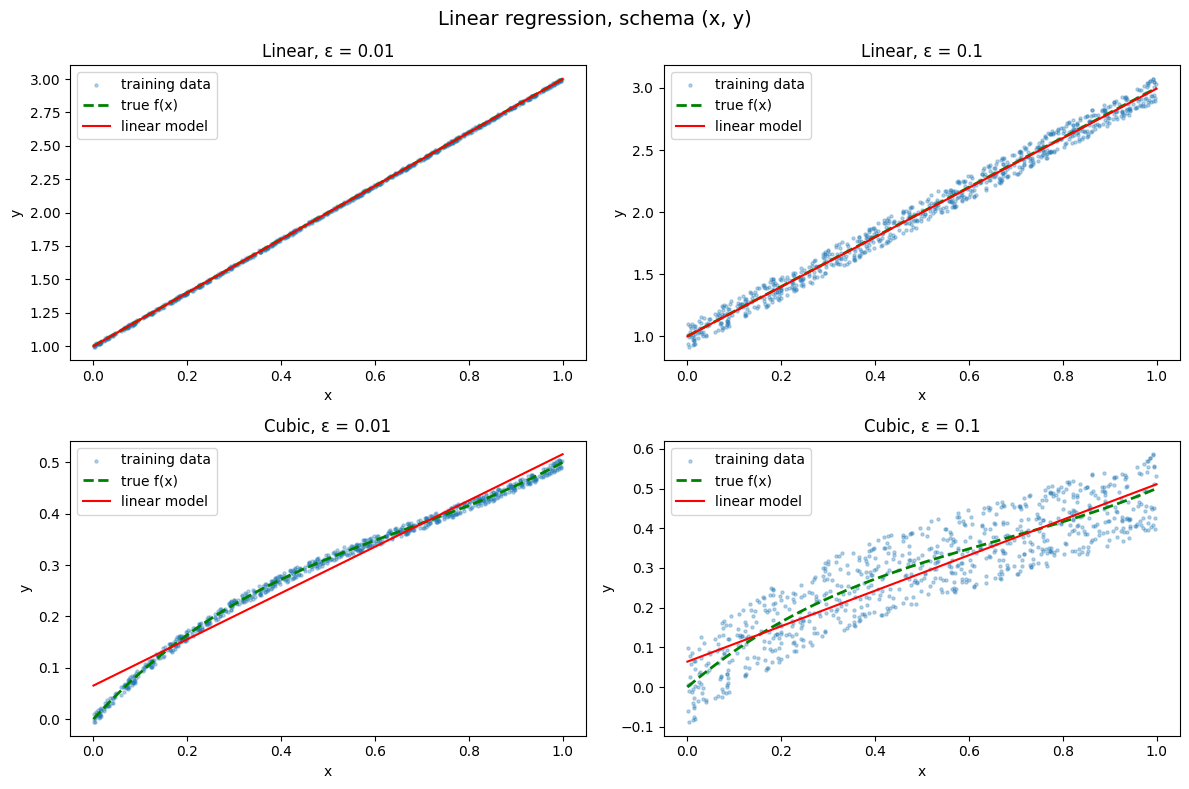

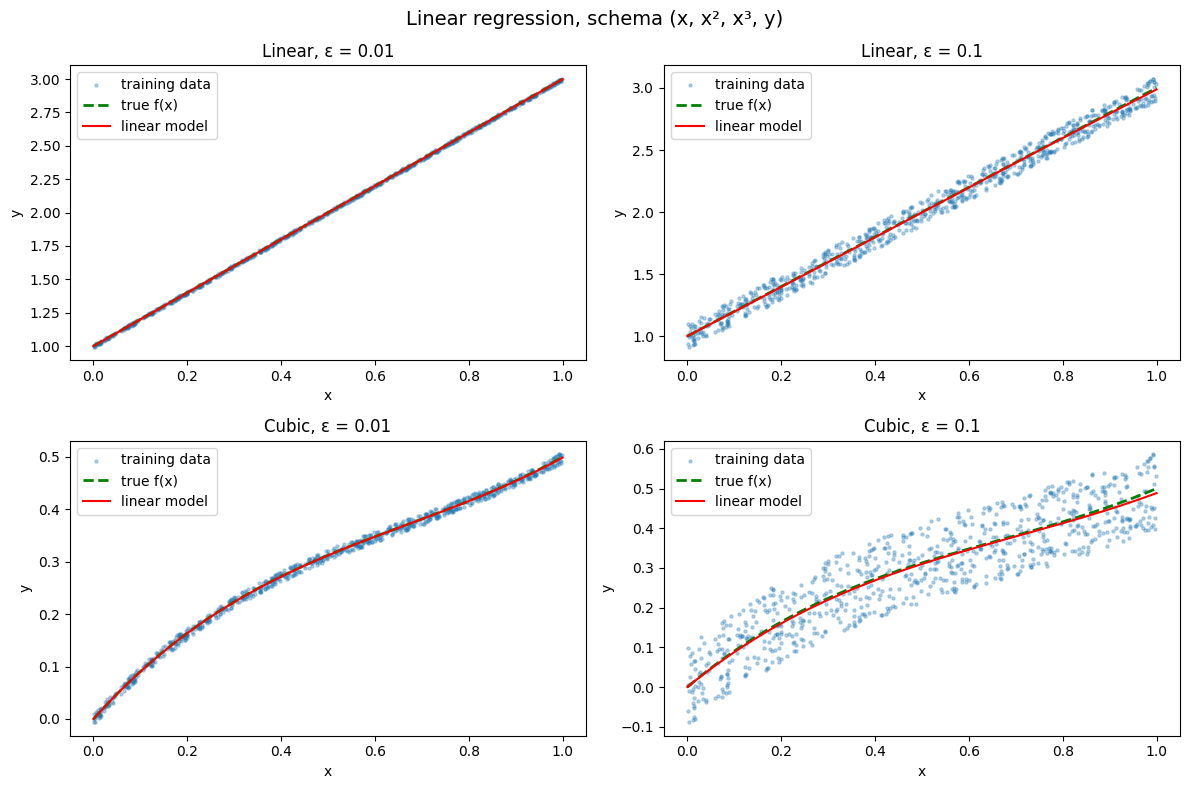

In [4]:
linear_results = []
linear_models = {}

for s_name, funcs in schemas.items():
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for row, (f_name, f) in enumerate(true_functions.items()):
        for col, noise in enumerate(noise_levels):
            X_train, X_test, y_train, y_test = datasets[(f_name, noise, s_name)]
            beta = fit(X_train, y_train)
            linear_models[(f_name, noise, s_name)] = beta

            # error at x = 10 against the noise-free value f(10)
            pred_10 = predict(beta, make_features([10.0], funcs))[0]

            linear_results.append({
                'function': f_name, 'noise': noise, 'schema': s_name,
                'train RMSE': evaluate_model(predict(beta, X_train), y_train),
                'test RMSE': evaluate_model(predict(beta, X_test), y_test),
                'f(10)': f(10.0), 'prediction at x=10': pred_10,
                'error at x=10': pred_10 - f(10.0),
            })

            ax = axes[row, col]
            ax.scatter(X_train['x'], y_train, s=5, alpha=0.3, label='training data')
            ax.plot(grid, f(grid), 'g--', linewidth=2, label='true f(x)')
            ax.plot(grid, predict(beta, make_features(grid, funcs)), 'r', linewidth=1.5, label='linear model')
            ax.set_title(f'{f_name}, ε = {noise}')
            ax.set_xlabel('x')
            ax.set_ylabel('y')
            ax.legend()
    fig.suptitle(f'Linear regression, schema {s_name}', fontsize=14)
    fig.tight_layout()
    plt.show()

linear_results = pd.DataFrame(linear_results)

### Learned coefficients

β₀ is the intercept, β₁…β₃ multiply x, x², x³. True coefficients: linear `[1, 2]`, cubic `[0, 1, −1, 0.5]`.

In [5]:
coef_table = pd.DataFrame(
    {key: pd.Series(beta, index=[f'β{i}' for i in range(len(beta))]) for key, beta in linear_models.items()}
).T
coef_table.index.names = ['function', 'noise', 'schema']
coef_table.round(4)

β0      β1      β2      β3
function noise schema                                        
Linear   0.01  (x, y)          0.9999  1.9996     NaN     NaN
         0.10  (x, y)          0.9985  1.9957     NaN     NaN
Cubic    0.01  (x, y)          0.0652  0.4506     NaN     NaN
         0.10  (x, y)          0.0639  0.4468     NaN     NaN
Linear   0.01  (x, x², x³, y)  1.0000  1.9962  0.0103 -0.0077
         0.10  (x, x², x³, y)  1.0002  1.9622  0.1030 -0.0769
Cubic    0.01  (x, x², x³, y)  0.0000  0.9962 -0.9897  0.4923
         0.10  (x, x², x³, y)  0.0002  0.9622 -0.8970  0.4231

## Q5: Error at (x, y) = (10, f(10))

x = 10 is far outside the training range [0, 1], so this measures extrapolation. The error is prediction − f(10), using the noise-free f(10).

In [6]:
linear_results[['function', 'noise', 'schema', 'f(10)', 'prediction at x=10', 'error at x=10']].round(4)

,function,noise,schema,f(10),prediction at x=10,error at x=10
0,Linear,0.01,"(x, y)",21.0,20.9956,-0.0044
1,Linear,0.10,"(x, y)",21.0,20.9559,-0.0441
2,Cubic,0.01,"(x, y)",410.0,4.5716,-405.4284
3,Cubic,0.10,"(x, y)",410.0,4.5319,-405.4681
4,Linear,0.01,"(x, x², x³, y)",21.0,14.2991,-6.7009
5,Linear,0.10,"(x, x², x³, y)",21.0,-46.0091,-67.0091
6,Cubic,0.01,"(x, x², x³, y)",410.0,403.2991,-6.7009
7,Cubic,0.10,"(x, x², x³, y)",410.0,342.9909,-67.0091


## Q6c: Irreducible error

The noise is uniform on [−ε, ε], so its variance is ε²/3. Even the true function f has expected squared error ε²/3, so the lowest achievable RMSE is **ε/√3**.

In [7]:
linear_results['irreducible RMSE (ε/√3)'] = linear_results['noise'] / np.sqrt(3)
linear_results[['function', 'noise', 'schema', 'train RMSE', 'test RMSE', 'irreducible RMSE (ε/√3)']].round(4)

,function,noise,schema,train RMSE,test RMSE,irreducible RMSE (ε/√3)
0,Linear,0.01,"(x, y)",0.0059,0.0059,0.0058
1,Linear,0.10,"(x, y)",0.0592,0.0589,0.0577
2,Cubic,0.01,"(x, y)",0.0220,0.0183,0.0058
3,Cubic,0.10,"(x, y)",0.0629,0.0607,0.0577
4,Linear,0.01,"(x, x², x³, y)",0.0059,0.0059,0.0058
5,Linear,0.10,"(x, x², x³, y)",0.0592,0.0589,0.0577
6,Cubic,0.01,"(x, x², x³, y)",0.0059,0.0059,0.0058
7,Cubic,0.10,"(x, x², x³, y)",0.0592,0.0589,0.0577


## Q7: Adding higher-order monomials

Cubic true function, ε = 0.1, 1000 records. Schemas go from `(x, y)` to `(x, x², …, x¹⁰, y)`.

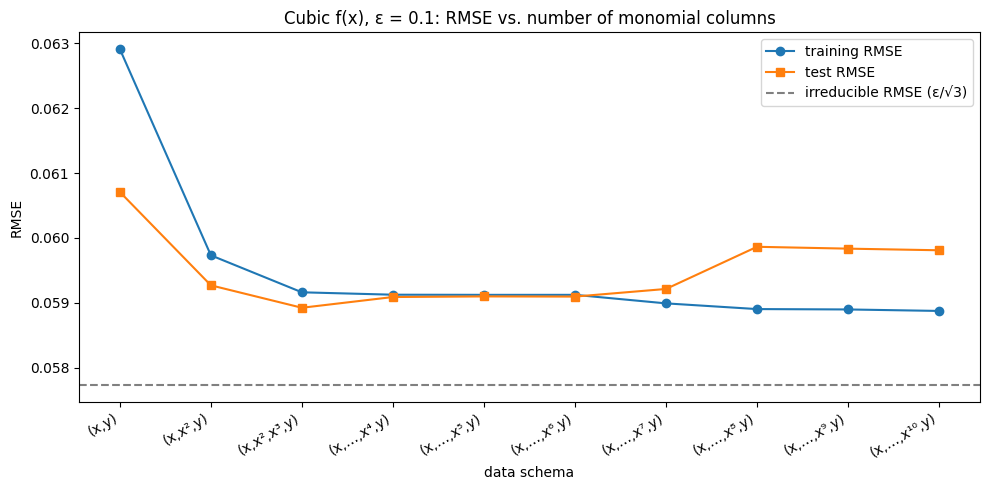

,degree,train RMSE,test RMSE,cond(XᵀX)
0,1,0.06291,0.06071,1.918952e+01
1,2,0.05973,0.05927,5.185590e+02
2,3,0.05916,0.05892,1.493832e+04
3,4,0.05912,0.05909,4.505377e+05
4,5,0.05912,0.05910,1.417966e+07
5,6,0.05912,0.05910,4.630929e+08
6,7,0.05899,0.05921,1.474723e+10
7,8,0.05890,0.05986,5.012362e+11
8,9,0.05890,0.05983,1.681940e+13
9,10,0.05887,0.05981,5.500075e+14


In [8]:
f_cubic = true_functions['Cubic']
max_degree = 10

degree_results = []
for degree in range(1, max_degree + 1):
    # extra columns x^2 ... x^degree (k=k binds the current exponent)
    funcs = [lambda x, k=k: x**k for k in range(2, degree + 1)]
    X, y = generate_noisy_dataset(funcs, f_cubic, (0.0, 1.0), N_SAMPLES, 0.1, seed=SEED)
    X_train, X_test, y_train, y_test = split_dataset(X, y)
    beta = fit(X_train, y_train)

    # condition number of XᵀX: large values mean the matrix inverse is numerically unstable
    X_aug = add_intercept(X_train)
    degree_results.append({
        'degree': degree,
        'train RMSE': evaluate_model(predict(beta, X_train), y_train),
        'test RMSE': evaluate_model(predict(beta, X_test), y_test),
        'cond(XᵀX)': np.linalg.cond(X_aug.T @ X_aug),
    })

degree_results = pd.DataFrame(degree_results)

# schema labels: (x,y), (x,x²,y), (x,x²,x³,y), (x,…,x⁴,y), …
sup = str.maketrans('0123456789', '⁰¹²³⁴⁵⁶⁷⁸⁹')
labels = ['(x,y)', '(x,x²,y)', '(x,x²,x³,y)'] + [f'(x,…,x{str(d).translate(sup)},y)'
                                               for d in range(4, max_degree + 1)]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(degree_results['degree'], degree_results['train RMSE'], 'o-', label='training RMSE')
ax.plot(degree_results['degree'], degree_results['test RMSE'], 's-', label='test RMSE')
ax.axhline(0.1 / np.sqrt(3), color='gray', linestyle='--', label='irreducible RMSE (ε/√3)')
ax.set_xticks(degree_results['degree'])
ax.set_xticklabels(labels, rotation=30, ha='right')
ax.set_xlabel('data schema')
ax.set_ylabel('RMSE')
ax.set_title('Cubic f(x), ε = 0.1: RMSE vs. number of monomial columns')
ax.legend()
plt.tight_layout()
plt.show()

degree_results.round(5)

## Q9: Regression trees

Same training and test sets as the linear models, for `min_records` ∈ {1000, 50, 1}. Each panel shows the training data, the true function, the tree's prediction and its split points.

With 800 training records, `min_records = 1000` never splits (a single leaf predicting the mean), and `min_records = 1` splits until every leaf is pure.

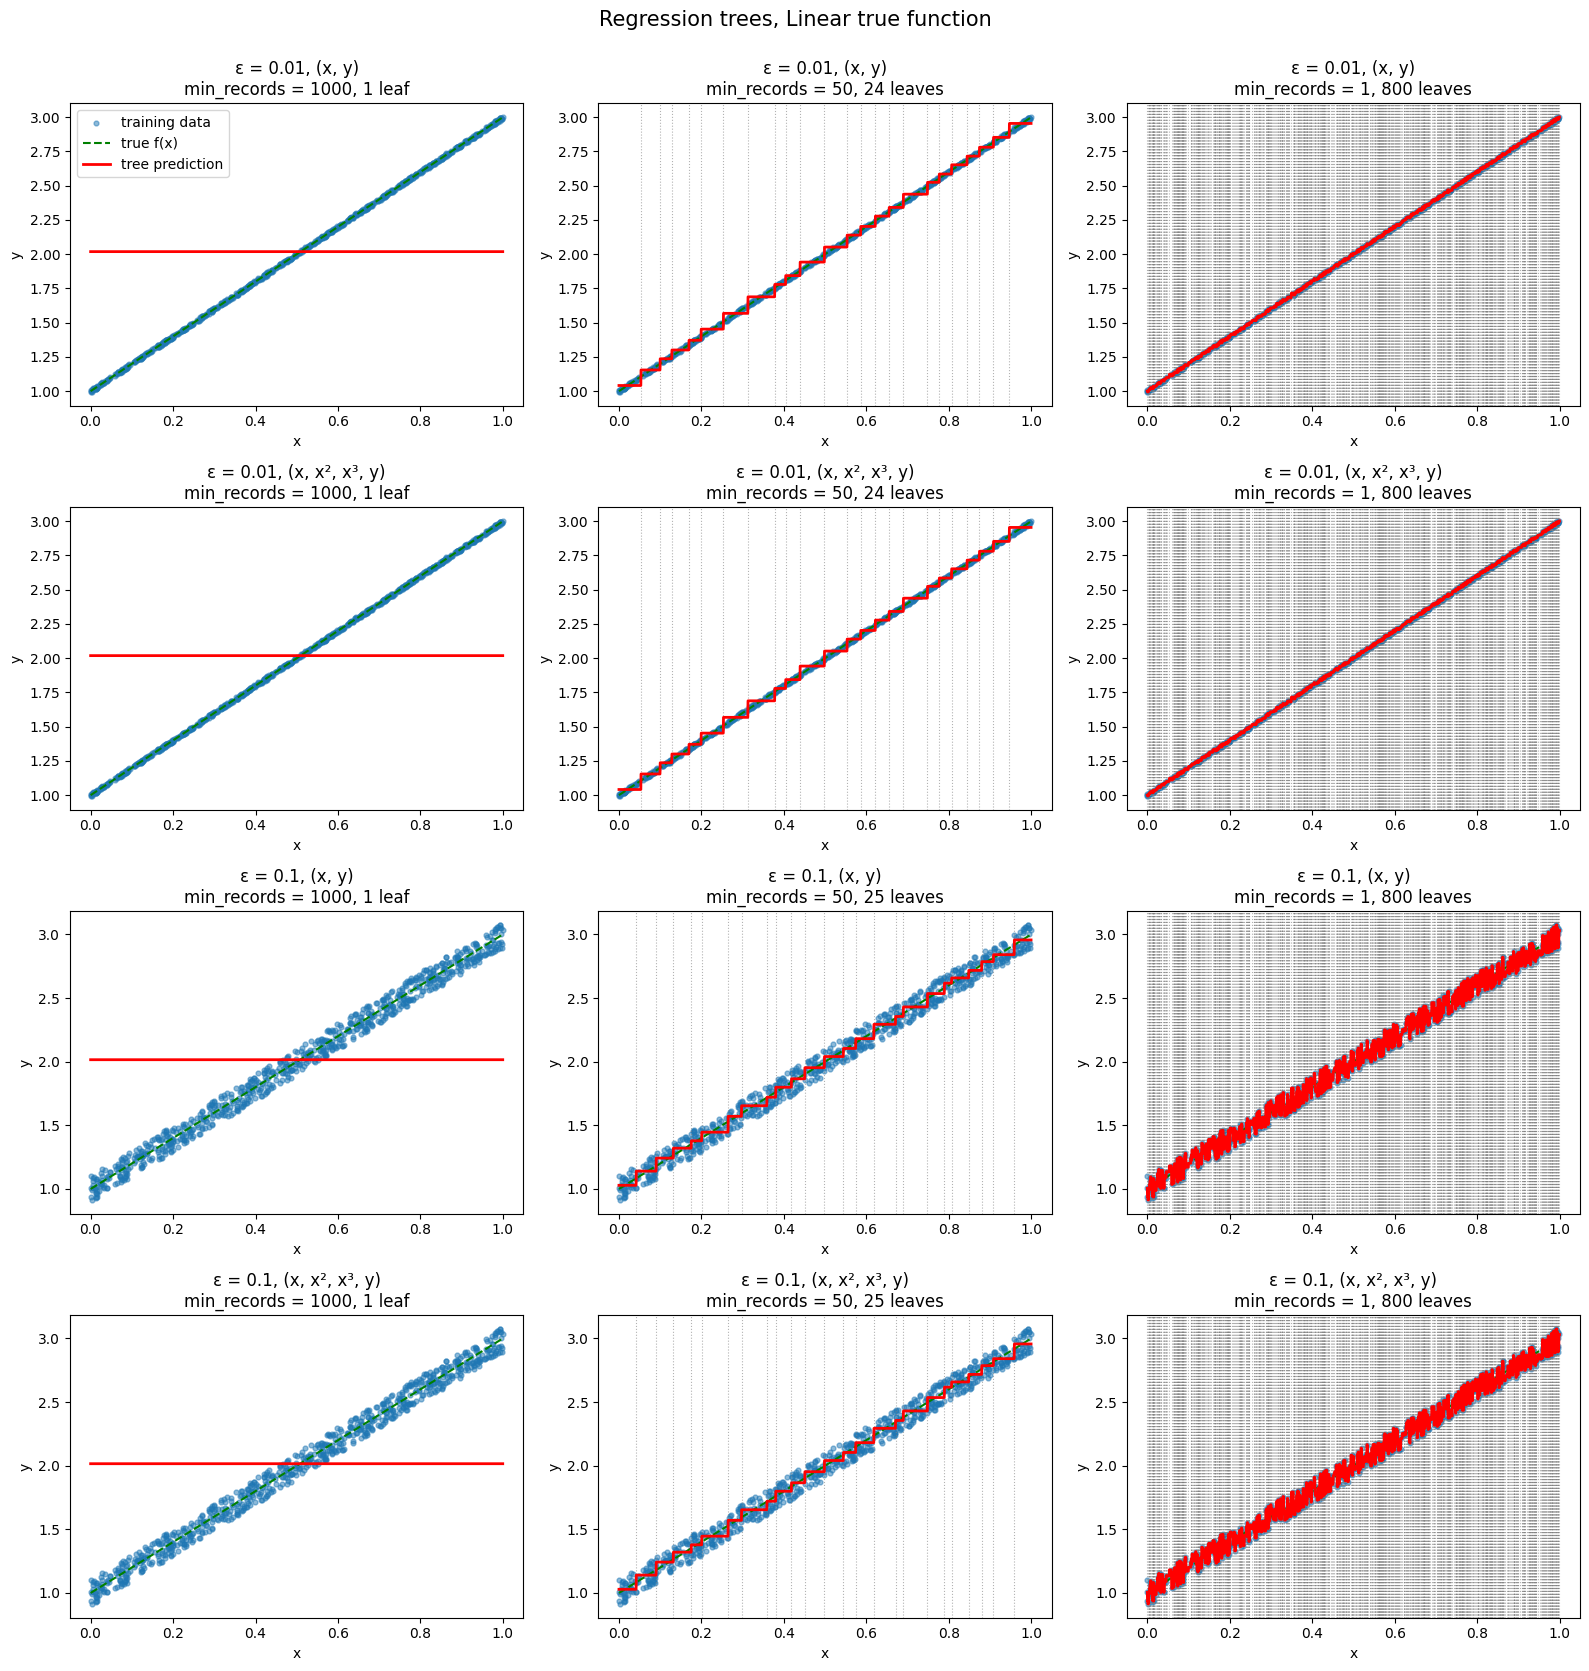

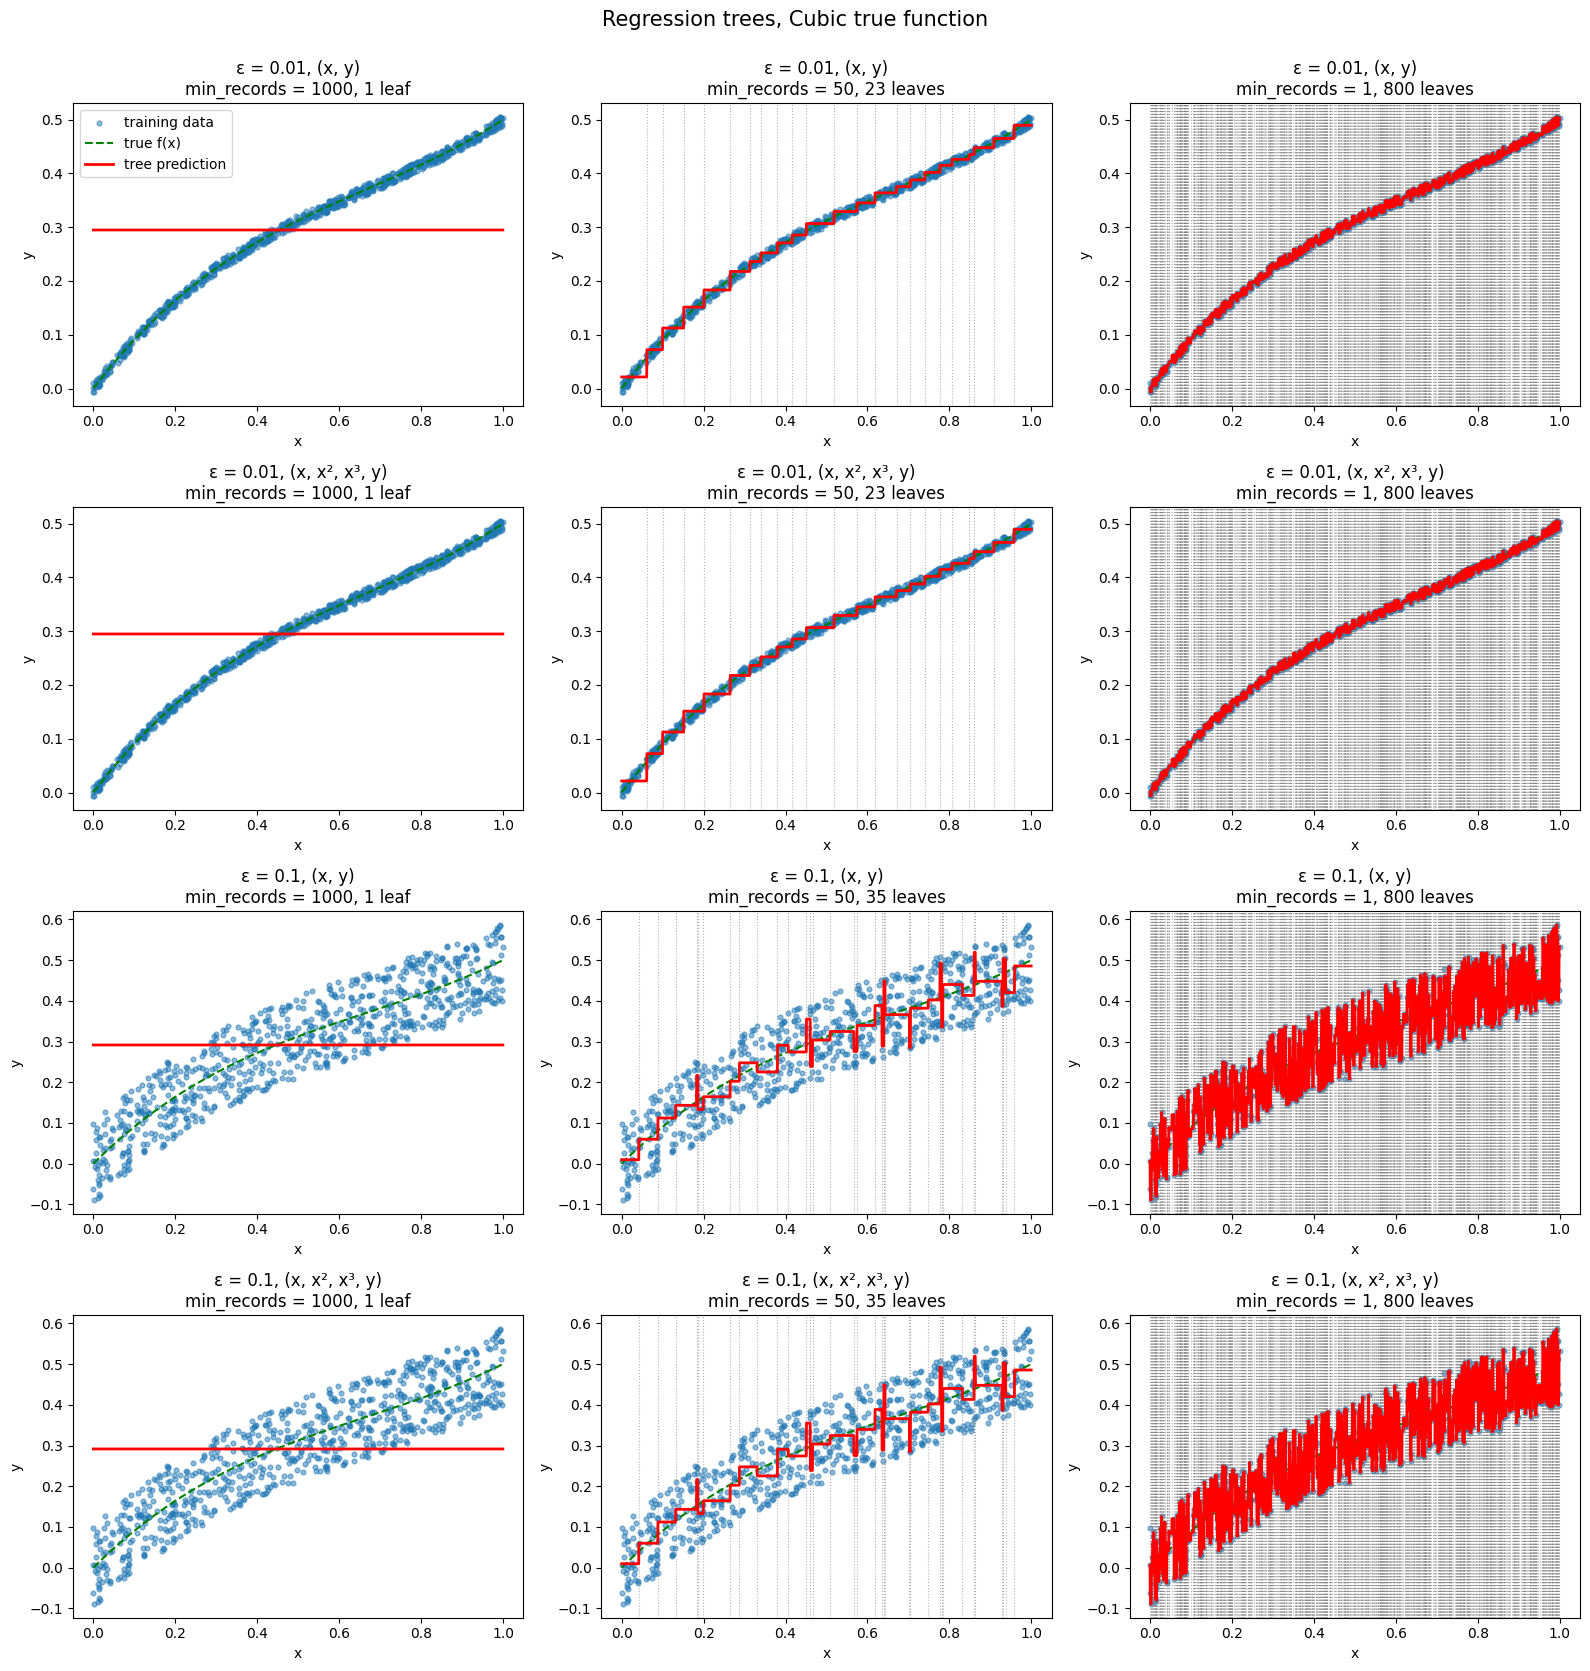

In [9]:
min_records_list = [1000, 50, 1]


def leaf_sizes(tree, X):
    # route each training record down the tree and count records per leaf
    counts = {}
    for row in np.asarray(X[tree.columns], dtype=float):
        node = tree.root
        while not node.is_leaf():
            node = node.left if row[node.attribute] <= node.split else node.right
        counts[id(node)] = counts.get(id(node), 0) + 1
    return np.array(list(counts.values()))


tree_results = []
for f_name, f in true_functions.items():
    fig, axes = plt.subplots(4, 3, figsize=(16, 17))
    panel_rows = [(noise, s_name) for noise in noise_levels for s_name in schemas]
    for row, (noise, s_name) in enumerate(panel_rows):
        X_train, X_test, y_train, y_test = datasets[(f_name, noise, s_name)]
        for col, mr in enumerate(min_records_list):
            tree = RegressionTree().fit((X_train, y_train), min_records=mr)
            sizes = leaf_sizes(tree, X_train)
            tree_results.append({
                'function': f_name, 'noise': noise, 'schema': s_name, 'min_records': mr,
                'train RMSE': evaluate_model(tree.predict(X_train), y_train),
                'test RMSE': evaluate_model(tree.predict(X_test), y_test),
                'nodes': 2 * tree.n_leaves() - 1, 'leaves': tree.n_leaves(),
                'records/leaf min': sizes.min(), 'records/leaf mean': sizes.mean(),
                'records/leaf max': sizes.max(),
            })

            ax = axes[row, col]
            tree.visualize(schemas[s_name], true_function=f, ax=ax)
            leaves = f'{tree.n_leaves()} ' + ('leaf' if tree.n_leaves() == 1 else 'leaves')
            ax.set_title(f'ε = {noise}, {s_name}\nmin_records = {mr}, {leaves}')
            if (row, col) != (0, 0):
                ax.get_legend().remove()
    fig.suptitle(f'Regression trees, {f_name} true function', fontsize=15)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

tree_results = pd.DataFrame(tree_results)

### Tree size and RMSE

In [10]:
tree_results.round(4)

,function,noise,schema,min_records,train RMSE,test RMSE,nodes,leaves,records/leaf min,records/leaf mean,records/leaf max
0,Linear,0.01,"(x, y)",1000,0.5835,0.5088,1,1,800,800.0000,800
1,Linear,0.01,"(x, y)",50,0.0244,0.0285,47,24,21,33.3333,47
2,Linear,0.01,"(x, y)",1,0.0000,0.0091,1599,800,1,1.0000,1
3,Linear,0.01,"(x, x², x³, y)",1000,0.5835,0.5088,1,1,800,800.0000,800
4,Linear,0.01,"(x, x², x³, y)",50,0.0244,0.0285,47,24,21,33.3333,47
5,Linear,0.01,"(x, x², x³, y)",1,0.0000,0.0091,1599,800,1,1.0000,1
6,Linear,0.10,"(x, y)",1000,0.5853,0.5143,1,1,800,800.0000,800
7,Linear,0.10,"(x, y)",50,0.0570,0.0658,49,25,13,32.0000,44
8,Linear,0.10,"(x, y)",1,0.0000,0.0867,1599,800,1,1.0000,1
9,Linear,0.10,"(x, x², x³, y)",1000,0.5853,0.5143,1,1,800,800.0000,800


## Q10: Trees vs. linear models

Test RMSE on the same test sets. `linear` is the linear model for that dataset; the other columns are trees by `min_records`.

In [11]:
comparison = tree_results.pivot_table(index=['function', 'noise', 'schema'],
                                      columns='min_records', values='test RMSE')
comparison = comparison[min_records_list]
comparison.columns = [f'tree, min_records={mr}' for mr in min_records_list]
comparison.insert(0, 'linear', linear_results.set_index(['function', 'noise', 'schema'])['test RMSE'])
comparison['irreducible (ε/√3)'] = comparison.index.get_level_values('noise') / np.sqrt(3)
comparison.round(4)

linear  tree, min_records=1000  \
function noise schema                                           
Cubic    0.01  (x, x², x³, y)  0.0059                  0.1100   
               (x, y)          0.0183                  0.1100   
         0.10  (x, x², x³, y)  0.0589                  0.1263   
               (x, y)          0.0607                  0.1263   
Linear   0.01  (x, x², x³, y)  0.0059                  0.5088   
               (x, y)          0.0059                  0.5088   
         0.10  (x, x², x³, y)  0.0589                  0.5143   
               (x, y)          0.0589                  0.5143   

                               tree, min_records=50  tree, min_records=1  \
function noise schema                                                      
Cubic    0.01  (x, x², x³, y)                0.0097               0.0087   
               (x, y)                        0.0097               0.0087   
         0.10  (x, x², x³, y)                0.0638               0.0865   
               (x, y)                        0.0638               0.0865   
Linear   0.01  (x, x², x³, y)                0.0285               0.0091   
               (x, y)                        0.0285               0.0091   
         0.10  (x, x², x³, y)                0.0658               0.0867   
               (x, y)                        0.0658               0.0867   

                               irreducible (ε/√3)  
function noise schema                              
Cubic    0.01  (x, x², x³, y)              0.0058  
               (x, y)                      0.0058  
         0.10  (x, x², x³, y)              0.0577  
               (x, y)                      0.0577  
Linear   0.01  (x, x², x³, y)              0.0058  
               (x, y)                      0.0058  
         0.10  (x, x², x³, y)              0.0577  
               (x, y)                      0.0577

## Q11: Overfitting study

200 records from `f(x) = sin(2πx)` with ε = 0.2, schema `(x, y)`, same fixed 80/20 split.

The training set has 160 records, so `min_records = 256` never splits and gives a single leaf.

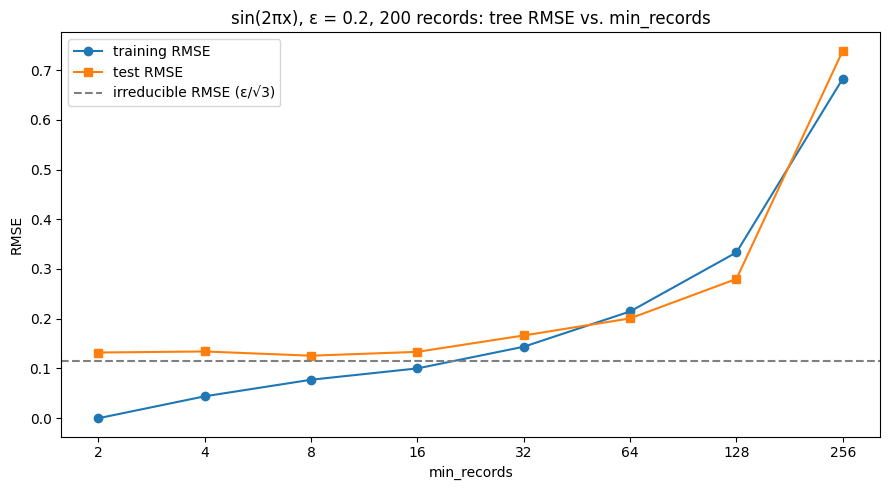

,min_records,leaves,train RMSE,test RMSE
0,2,160,0.0000,0.1321
1,4,81,0.0441,0.1342
2,8,37,0.0774,0.1257
3,16,17,0.1002,0.1335
4,32,9,0.1437,0.1664
5,64,5,0.2146,0.2007
6,128,2,0.3333,0.2801
7,256,1,0.6827,0.7389


In [12]:
f_sin = lambda x: np.sin(2 * np.pi * x)
X, y = generate_noisy_dataset([], f_sin, (0.0, 1.0), 200, 0.2, seed=SEED)
X_train, X_test, y_train, y_test = split_dataset(X, y)

overfit_results = []
for mr in [2, 4, 8, 16, 32, 64, 128, 256]:
    tree = RegressionTree().fit((X_train, y_train), min_records=mr)
    overfit_results.append({
        'min_records': mr, 'leaves': tree.n_leaves(),
        'train RMSE': evaluate_model(tree.predict(X_train), y_train),
        'test RMSE': evaluate_model(tree.predict(X_test), y_test),
    })
overfit_results = pd.DataFrame(overfit_results)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(overfit_results['min_records'], overfit_results['train RMSE'], 'o-', label='training RMSE')
ax.plot(overfit_results['min_records'], overfit_results['test RMSE'], 's-', label='test RMSE')
ax.axhline(0.2 / np.sqrt(3), color='gray', linestyle='--', label='irreducible RMSE (ε/√3)')
ax.set_xscale('log', base=2)
ax.set_xticks(overfit_results['min_records'])
ax.set_xticklabels(overfit_results['min_records'])
ax.set_xlabel('min_records')
ax.set_ylabel('RMSE')
ax.set_title('sin(2πx), ε = 0.2, 200 records: tree RMSE vs. min_records')
ax.legend()
plt.tight_layout()
plt.show()

overfit_results.round(4)